In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('data.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

<Axes: xlabel='diagnosis'>

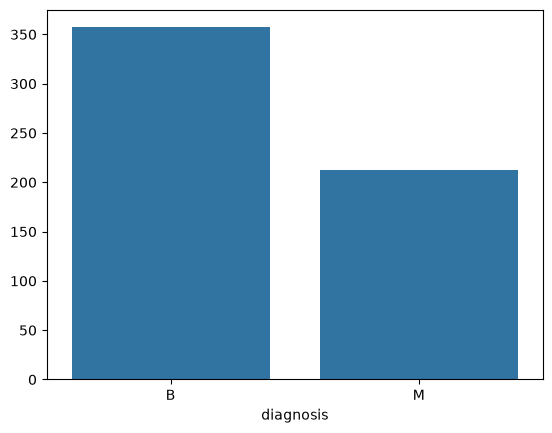

In [2]:
import seaborn as sns

diagnosisValues = df['diagnosis'].value_counts()
sns.barplot(x=diagnosisValues.index, y=diagnosisValues.values)

In [3]:
df = df.drop(columns=['id', 'Unnamed: 32'])
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [4]:
print(y.value_counts())

diagnosis
0    357
1    212
Name: count, dtype: int64


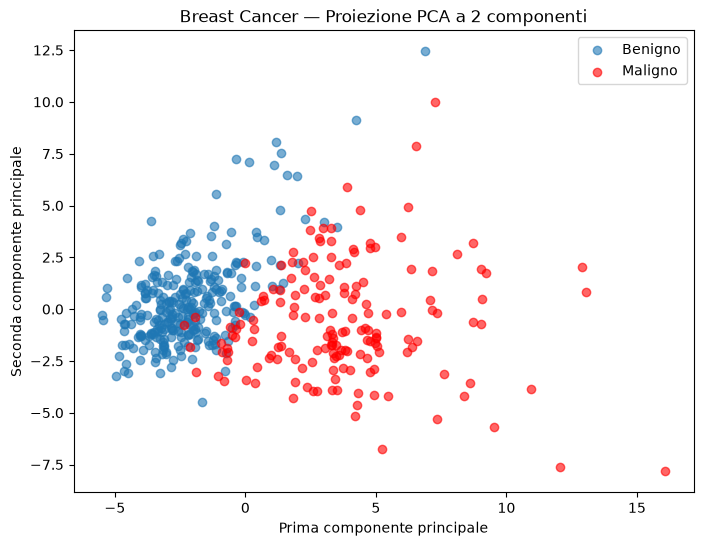

In [5]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)

plt.figure(figsize=(8,6))
plt.scatter(X_train_pca[y_train==0, 0], X_train_pca[y_train==0, 1], label='Benigno', alpha=0.6)
plt.scatter(X_train_pca[y_train==1, 0], X_train_pca[y_train==1, 1], label='Maligno', alpha=0.6, color='red')
plt.xlabel('Prima componente principale')
plt.ylabel('Seconda componente principale')
plt.title('Breast Cancer — Proiezione PCA a 2 componenti')
plt.legend()
plt.show()

In [6]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.svm import SVC

param_dist = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear', 'poly']
}

random_search = RandomizedSearchCV(SVC(), param_dist, n_iter=10, cv=5, scoring='accuracy', random_state=42)
random_search.fit(X_train_scaled, y_train)

print(f"Migliori parametri: {random_search.best_params_}")
print(f"Miglior accuracy in CV: {random_search.best_score_:.4f}")

Migliori parametri: {'kernel': 'linear', 'gamma': 0.01, 'C': 0.1}
Miglior accuracy in CV: 0.9736


In [7]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix

svm = SVC(kernel='rbf')
svm.fit(X_train_scaled, y_train)
y_pred = svm.predict(X_test_scaled)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.99        71
           1       1.00      0.95      0.98        43

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

[[71  0]
 [ 2 41]]


In [8]:
from sklearn.metrics import accuracy_score

# Modello scelto dalla ricerca, valutato sul test
y_pred2 = random_search.best_estimator_.predict(X_test_scaled)

print(classification_report(y_test, y_pred2))
print(confusion_matrix(y_test, y_pred2))
print(f"Accuracy: {accuracy_score(y_test, y_pred2)}")

              precision    recall  f1-score   support

           0       0.97      1.00      0.99        71
           1       1.00      0.95      0.98        43

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

[[71  0]
 [ 2 41]]
Accuracy: 0.9824561403508771
